# Refrigeration fault-type classifier

Run all cells from the project root. This LightGBM notebook predicts baseline or one of six fault scenarios using one-minute temperature features. It uses a seeded random 60/20/20 split within each labeled fault interval and holds out whole baseline recordings.

In [1]:
# Resolve repository-relative inputs from either the root or notebooks/.
import os
from pathlib import Path

if not Path("models").is_dir() and Path("../models").is_dir():
    os.chdir("..")

from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from lightgbm import LGBMClassifier
from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_curve, roc_auc_score

AIR = [
    "T-LTcase-Ret", "T-LTcase-Sup", "T-MTCase-Ret", "T-MTCase-Sup",
    "T-GC-Fan2-In", "T-GC-Fan2-Out",
]
LOOKBACK = 1  # completed one-minute bins per feature vector
# Optional verified fault-active intervals keyed by filename stem.
# Use [(start, end), ...] with full timestamps and exclusive ends.
FAULT_INTERVALS = {}
ALLOW_WEAK_LABELS = True
BASELINE_VALIDATION = "BaselineTestD"
BASELINE_TEST = "BaselineTestE"

paths = sorted(Path("data").glob("*.csv"))
if sum(p.stem.startswith("Fault") for p in paths) != 6 or sum(
    p.stem.startswith("BaselineTest") for p in paths
) != 5:
    raise ValueError("Expected the six fault and five baseline CSVs under data/.")

## Construct one-minute windows

Aggregate all readings in each recorded minute, retaining file order for first-to-last change where timestamps repeat. Compute the median, population standard deviation and first-to-last change for the six channels and three air temperature differences. Require at least two readings per quantity. A prediction is available at the end of each minute. Randomly assign distinct one-minute windows within each fault interval to train, validation and test. Adjacent windows may land in different splits.

In [2]:
def make_windows(path):
    raw = pd.read_csv(path, usecols=["Timestamp", *AIR])
    stamps = pd.to_datetime(raw.pop("Timestamp"), format="mixed", errors="raise")
    raw = raw.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    raw["Freezer air drop"] = raw[AIR[0]] - raw[AIR[1]]
    raw["Chilled air drop"] = raw[AIR[2]] - raw[AIR[3]]
    raw["Gas cooler air rise"] = raw[AIR[5]] - raw[AIR[4]]
    ordered = raw.iloc[np.argsort(stamps.to_numpy(), kind="stable")]
    bins = stamps.sort_values(kind="stable").dt.floor("min")
    grouped = ordered.groupby(bins)
    minute = grouped.median()
    features = pd.concat([
        minute.add_suffix(" median"),
        grouped.std(ddof=0).add_suffix(" std"),
        (grouped.last() - grouped.first()).add_suffix(" change"),
    ], axis=1)
    features = features.loc[grouped.count().ge(2).all(axis=1)].copy()
    features["End"] = features.index + pd.Timedelta(minutes=1)
    features["Start"] = features["End"] - pd.Timedelta(minutes=LOOKBACK)
    run = path.stem
    features["Run"] = run
    features["Anomaly"] = int(run.startswith("Fault"))
    if not run.startswith("Fault"):
        features["Split"] = {
            BASELINE_VALIDATION: "validation", BASELINE_TEST: "test",
        }.get(run, "train")
        features["Label source"] = "baseline recording"
        return features

    if run in FAULT_INTERVALS:
        intervals = [(pd.Timestamp(begin), pd.Timestamp(end)) for begin, end in FAULT_INTERVALS[run]]
        features["Label source"] = "supplied fault interval"
    elif ALLOW_WEAK_LABELS:
        intervals = [(minute.index.min(), minute.index.max() + pd.Timedelta(minutes=1))]
        features["Label source"] = "fault recording proxy"
    else:
        return features.iloc[:0]

    rng = np.random.default_rng(42 + int(run.split("_")[0].removeprefix("Fault")))
    features["Split"] = "unlabeled"
    for begin, end in sorted(intervals):
        if begin >= end:
            raise ValueError(f"Invalid interval in {run}: {begin} to {end}")
        inside = features["Start"].ge(begin) & features["End"].le(end)
        if (inside & features["Split"].ne("unlabeled")).any():
            raise ValueError(f"Overlapping labeled windows in {run}")
        selected = rng.permutation(features.index[inside])
        first, second = int(len(selected) * .60), int(len(selected) * .80)
        for split, indexes in zip(
            ("train", "validation", "test"), np.split(selected, [first, second])
        ):
            features.loc[indexes, "Split"] = split
    return features.loc[features["Split"].ne("unlabeled")]


windows = pd.concat([make_windows(path) for path in paths], ignore_index=True)
metadata = ["Run", "Start", "End", "Split", "Anomaly", "Label source"]
feature_names = windows.columns.drop(metadata).tolist()
display(windows.groupby(["Run", "Label source", "Split"]).size().unstack(fill_value=0))

train, validation, test = [windows.loc[windows["Split"].eq(split)].copy()
                           for split in ("train", "validation", "test")]
for frame in (train, validation, test):
    if frame["Anomaly"].nunique() != 2:
        raise ValueError("Each split needs both classes. Review fault intervals and split boundaries.")
assert not windows.duplicated(["Run", "Start"]).any()


,Split,test,train,validation
Run,Label source,,,
BaselineTestA,baseline recording,0,1440,0
BaselineTestB,baseline recording,0,1440,0
BaselineTestC,baseline recording,0,1440,0
BaselineTestD,baseline recording,0,0,1440
BaselineTestE,baseline recording,1440,0,0
Fault1_DisplayCaseDoorOpen,fault recording proxy,288,864,288
Fault2_IceAccumulation,fault recording proxy,288,864,288
Fault3_EvapValveFailure,fault recording proxy,288,864,288
Fault4_MTEvapFanFailure,fault recording proxy,288,864,288


## Held-out fault-type evaluation

The seven-class model uses the one-minute features and held-out split above. It predicts baseline or one of six fault scenarios. With weak run labels and one recording per fault, the confusion matrix measures same-recording scenario classification. Verified fault intervals and independent recordings are needed to establish performance on active faults in new runs.

Random assignment can put adjacent minutes into different splits. Results measure interpolation within these recordings and may be optimistic for continuous replay or new runs.

In [3]:
from sklearn.metrics import classification_report, confusion_matrix

fault_names = [
    "Baseline", "Freezer door open", "Evaporator ice accumulation",
    "Expansion valve failure", "Chilled-case evaporator fan failure",
    "Gas cooler airflow blockage", "Chilled-case evaporator airflow blockage",
]

def scenario_ids(frame):
    return frame["Run"].str.extract(r"^Fault(\d+)_", expand=False).fillna(0).astype(int)

classes = list(range(len(fault_names)))
if sorted(scenario_ids(train).unique()) != classes:
    raise ValueError("Training needs examples of baseline and all six faults. Check the labeled intervals.")

fault_model = LGBMClassifier(
    objective="multiclass", n_estimators=100, learning_rate=0.05,
    num_leaves=15, min_child_samples=50, class_weight="balanced",
    random_state=42, n_jobs=2, verbosity=-1,
)
fault_model.fit(train[feature_names], scenario_ids(train))
actual = scenario_ids(test)
predicted = fault_model.predict(test[feature_names])
display(pd.DataFrame(
    confusion_matrix(actual, predicted, labels=classes),
    index=pd.Index(fault_names, name="Actual"),
    columns=pd.Index(fault_names, name="Predicted"),
))
print(classification_report(actual, predicted, labels=classes, target_names=fault_names, zero_division=0))


Predicted,Baseline,Freezer door open,Evaporator ice accumulation,Expansion valve failure,Chilled-case evaporator fan failure,Gas cooler airflow blockage,Chilled-case evaporator airflow blockage
Actual,,,,,,,
Baseline,1416,24,0,0,0,0,0
Freezer door open,3,276,0,0,0,5,4
Evaporator ice accumulation,0,0,288,0,0,0,0
Expansion valve failure,9,1,0,278,0,0,0
Chilled-case evaporator fan failure,0,0,0,0,288,0,0
Gas cooler airflow blockage,1,5,1,0,0,279,2
Chilled-case evaporator airflow blockage,7,17,0,0,0,3,261


                                          precision    recall  f1-score   support

                                Baseline       0.99      0.98      0.98      1440
                       Freezer door open       0.85      0.96      0.90       288
             Evaporator ice accumulation       1.00      1.00      1.00       288
                 Expansion valve failure       1.00      0.97      0.98       288
     Chilled-case evaporator fan failure       1.00      1.00      1.00       288
             Gas cooler airflow blockage       0.97      0.97      0.97       288
Chilled-case evaporator airflow blockage       0.98      0.91      0.94       288

                                accuracy                           0.97      3168
                               macro avg       0.97      0.97      0.97      3168
                            weighted avg       0.98      0.97      0.97      3168



## Model diagnostics

The error plot groups held-out windows by recorded hour. Marker size reflects sample count. SHAP uses the feature with the largest mean absolute contribution for the stated class. The learning curve refits the same model settings and uses the existing training and validation splits.

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
errors = test[["Run", "End"]].copy()
errors["Wrong"] = np.asarray(predicted) != np.asarray(actual)
# Group held-out predictions into one-hour segments within each recording.
errors["Hour"] = (errors["End"] - pd.Timedelta(minutes=1)).dt.hour
segments = errors.groupby(["Run", "Hour"])["Wrong"].agg(["mean", "size"])
for run, rows in segments.groupby(level="Run"):
    ax.scatter(rows.index.get_level_values("Hour"), 100 * rows["mean"],
               s=8 + rows["size"], alpha=.65, label=run.split("_")[0])
ax.set(title="Held-out classification error by hour", xlabel="Recorded hour of day",
       ylabel="Incorrect predictions (%)", ylim=(-3, 103), xticks=range(0, 24, 2))
ax.legend(frameon=False, ncol=4, fontsize=8)
plt.show()

# Native LightGBM TreeSHAP contributions are in raw-score (logit) units.
X = test[feature_names]
contributions = fault_model.booster_.predict(X, pred_contrib=True, num_threads=2)
# Select the expansion-valve class from the packed multiclass contributions.
contributions = contributions.reshape(len(X), len(fault_names), len(feature_names) + 1)[:, 3, :]
values = contributions[:, :-1]
feature = int(np.abs(values).mean(axis=0).argmax())
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.scatter(X.iloc[:, feature], values[:, feature], s=10, alpha=.32, color="#176b9b")
ax.axhline(0, color="#667684", lw=1)
ax.set(title="SHAP dependence ? " + fault_names[3],
       xlabel=feature_names[feature] + " (?F)", ylabel="SHAP contribution to raw score")
plt.show()


In [ ]:

import matplotlib.pyplot as plt
import lightgbm as lgb

# Record loss with the same model settings and the existing split.
history = {}
diagnostic_model = lgb.LGBMClassifier(**fault_model.get_params())
diagnostic_model.fit(
    train[feature_names], scenario_ids(train),
    eval_set=[(train[feature_names], scenario_ids(train)), (validation[feature_names], scenario_ids(validation))],
    eval_names=["Training", "Validation"], eval_metric="multi_logloss",
    callbacks=[lgb.record_evaluation(history)],
)

fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for split, metrics in history.items():
    losses = metrics["multi_logloss"]
    ax.plot(np.arange(1, len(losses) + 1), losses, label=split)
ax.set(title="LightGBM learning curve", xlabel="Boosting round", ylabel="Log loss")
ax.legend(frameon=False)
plt.show()


## Export and reuse

Run this cell after training. It saves a native LightGBM model and its prediction settings under `models/`. In another notebook, calculate the same one-minute features first. With a feature DataFrame named `features`, use:

```python
import json
from pathlib import Path
import lightgbm as lgb
import numpy as np

settings = json.loads(Path("models/fault.json").read_text(encoding="utf-8"))
classifier = lgb.Booster(model_file="models/fault.txt")
scores = classifier.predict(features[settings["feature_names"]])
class_positions = (scores.argmax(axis=1)).astype(int)
predictions = np.asarray(settings["labels"])[class_positions]
```


In [ ]:
import json
from lightgbm import Booster

export_dir = Path("models")
export_dir.mkdir(exist_ok=True)
model_path = export_dir / "fault.txt"
settings_path = export_dir / "fault.json"
settings = {
    "feature_names": feature_names,
    "input_channels": AIR,
    "window_minutes": LOOKBACK,
    "class_ids": fault_model.classes_.tolist(),
    "labels": fault_names,
}
fault_model.booster_.save_model(str(model_path))
settings_path.write_text(json.dumps(settings, indent=2) + "\n", encoding="utf-8")

# Verify the exported files reproduce the held-out predictions.
settings = json.loads(settings_path.read_text(encoding="utf-8"))
restored = Booster(model_file=str(model_path))
scores = restored.predict(test[settings["feature_names"]], num_threads=2)
np.testing.assert_allclose(scores, fault_model.booster_.predict(test[feature_names], num_threads=2))
np.testing.assert_array_equal((scores.argmax(axis=1)).astype(int), predicted)
print(f"Saved {model_path} and {settings_path}. Held-out predictions match.")


## UNO Q early-exit gate evaluation

This figure evaluates the separate ten-minute model shipped with the UNO Q app. Baseline predictions exit locally. Any predicted fault counts as a forward, even if the fault subtype differs. Fault labels come from recording scenarios. No endpoint is called.

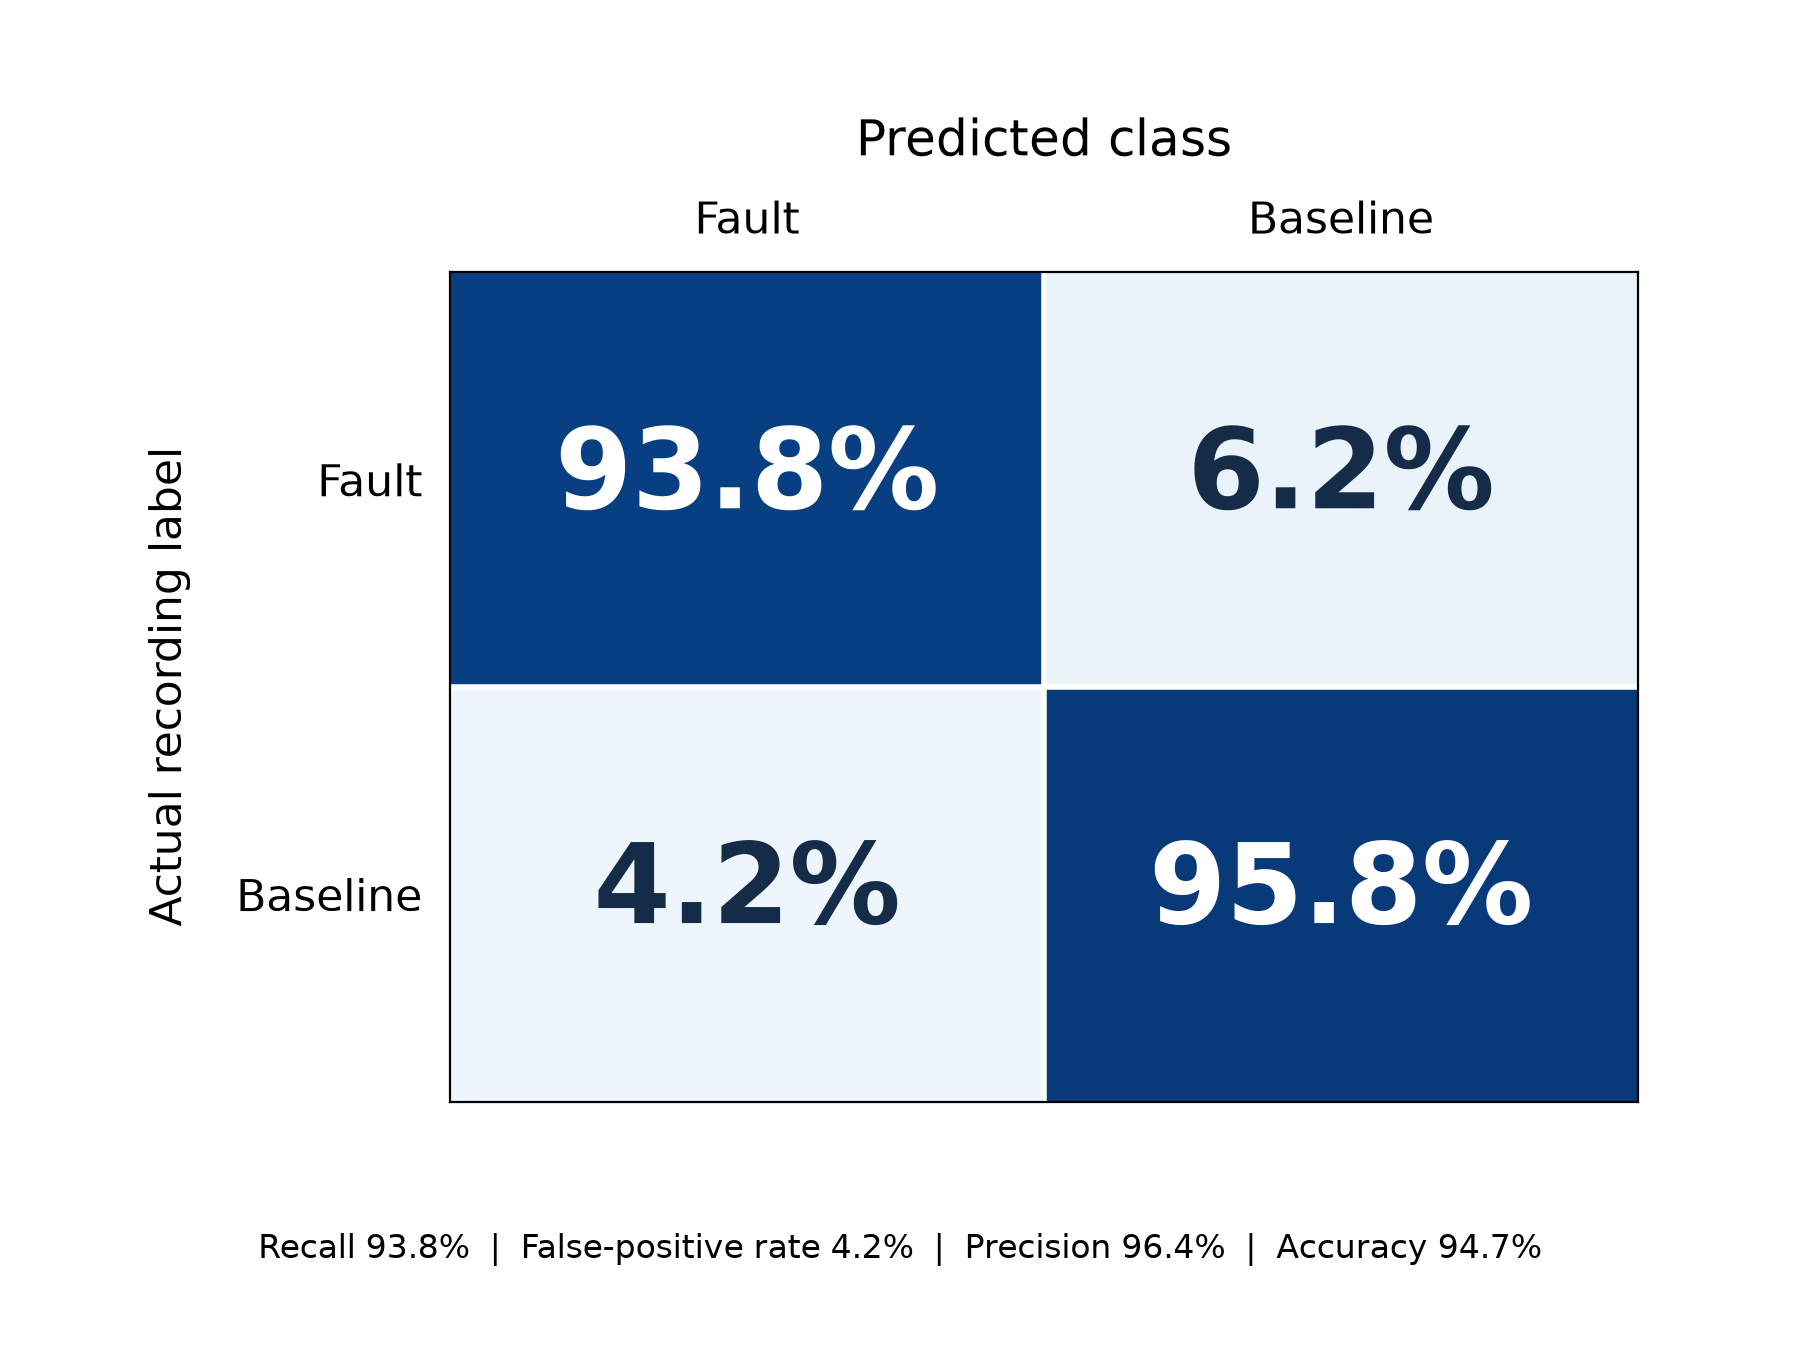

In [ ]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import numpy as np

app = Path("uno_q_app/fridge-fault-detector/python").resolve()
sys.path.insert(0, str(app))
try:
    from features import make_windows as edge_windows
    from lgbm_lite import Booster as EdgeBooster
finally:
    sys.path.remove(str(app))

config = json.loads((app / "models/demo_fault_10m.json").read_text())
edge = EdgeBooster(app / "models/demo_fault_10m.txt")
gate_counts = np.zeros((2, 2), dtype=int)
for recording in sorted((app / "data").glob("*.csv.gz")):
    minute, windows = edge_windows(recording, config["input_channels"], 10)
    elapsed = ((windows.index - minute.index.min()).total_seconds() / 60).astype(int)
    # Match the training script's test hours and select disjoint ten-minute windows.
    held_out = windows.loc[((elapsed // 60) % 5 == 4) & (elapsed % 10 == 9)]
    scores = edge.predict(held_out[config["feature_names"]].to_numpy())
    actual_gate = int(recording.name.startswith("Fault"))
    gate_counts[actual_gate] += np.bincount((scores.argmax(axis=1) != 0).astype(int), minlength=2)

tn, fp, fn, tp = gate_counts.ravel()
recall = tp / (tp + fn)
fpr = fp / (fp + tn)
precision = tp / (tp + fp) if tp + fp else float("nan")
accuracy = (tp + tn) / gate_counts.sum()
rates = gate_counts / gate_counts.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 6.8))
fig.subplots_adjust(left=.25, right=.91, top=.80, bottom=.19)
# Positive first, matching the reference layout.
ax.imshow(rates[::-1, ::-1], vmin=0, vmax=1, cmap="Blues", aspect="auto")
ax.set_xticks([0, 1], ["Fault", "Baseline"], fontsize=16)
ax.set_yticks([0, 1], ["Fault", "Baseline"], fontsize=16)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_xlabel("Predicted class", fontsize=18, labelpad=16)
ax.set_ylabel("Actual recording label", fontsize=16, labelpad=16)
ax.tick_params(axis="x", length=0, pad=10)
ax.tick_params(axis="y", length=0, pad=10)
ax.axhline(.5, color="white", linewidth=2)
ax.axvline(.5, color="white", linewidth=2)
for (row, col), value in np.ndenumerate(rates[::-1, ::-1]):
    ax.text(col, row, f"{value:.1%}", ha="center", va="center",
            fontsize=40, fontweight="bold",
            color="white" if value > .55 else "#142c47")
fig.text(.5, .075, f"Recall {recall:.1%}  |  False-positive rate {fpr:.1%}  |  Precision {precision:.1%}  |  Accuracy {accuracy:.1%}",
         fontsize=12, ha="center")
fig.savefig("images/edge_gate_confusion_matrix.png", dpi=200)
plt.show()


## Detection vs. diagnosis by fault

Same disjoint held-out ten-minute windows as the UNO Q gate matrix. Fault labels describe recording scenarios.

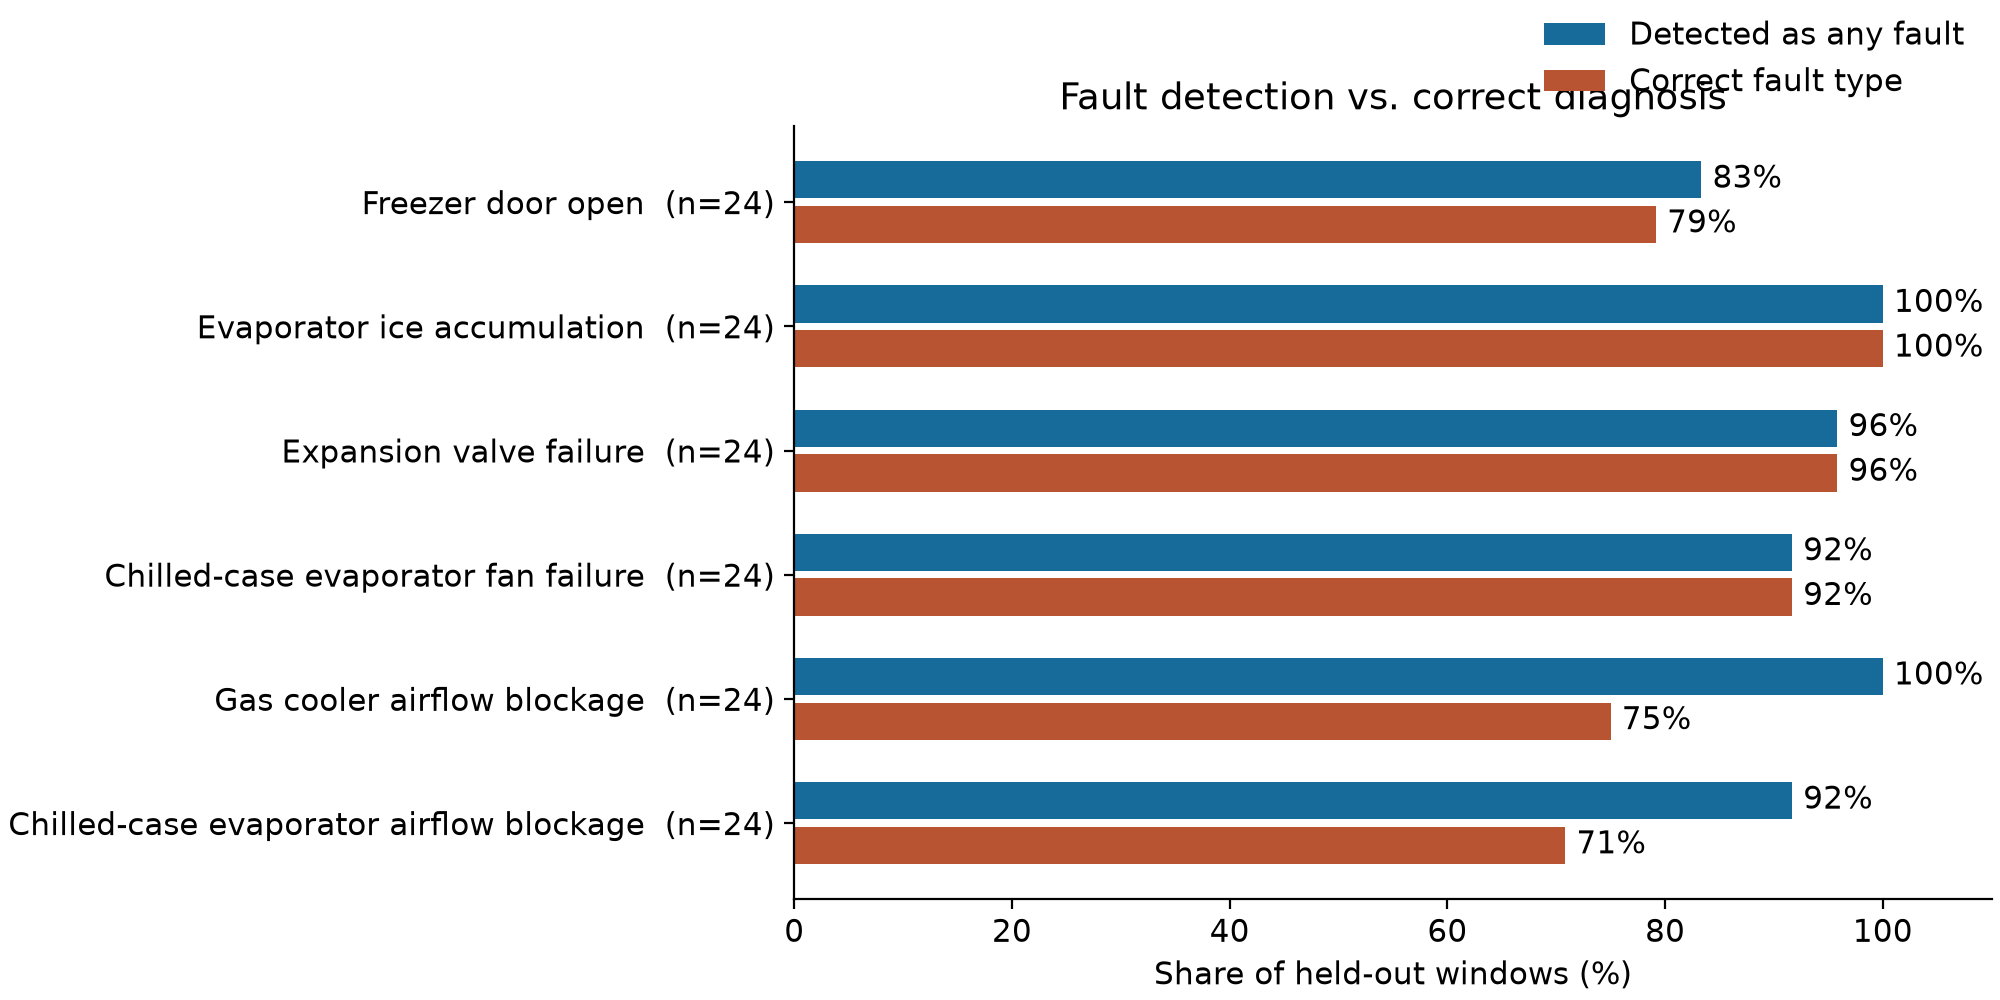

In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
blue, orange = "#176b9b", "#b95432"

# Uses the app model and held-out selection defined in the preceding gate cell.
comparison = []
for recording in sorted((app / "data").glob("Fault*.csv.gz")):
    minute, windows = edge_windows(recording, config["input_channels"], 10)
    elapsed = ((windows.index - minute.index.min()).total_seconds() / 60).astype(int)
    held_out = windows.loc[((elapsed // 60) % 5 == 4) & (elapsed % 10 == 9)]
    prediction = edge.predict(held_out[config["feature_names"]].to_numpy()).argmax(axis=1)
    actual = int(recording.name[5])
    comparison.append((config["labels"][actual], 100 * (prediction != 0).mean(),
                       100 * (prediction == actual).mean(), len(prediction)))
assert sum(row[3] for row in comparison) == gate_counts[1].sum()
labels, detected, diagnosed, counts = zip(*comparison)
y = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
for values, offset, label, color in [
    (detected, -.18, "Detected as any fault", blue), (diagnosed, .18, "Correct fault type", orange)
]:
    bars = ax.barh(y + offset, values, height=.30, color=color, label=label)
    ax.bar_label(bars, labels=[f"{value:.0f}%" for value in values], padding=4)
ax.set_yticks(y, [f"{label}  (n={count})" for label, count in zip(labels, counts)])
ax.invert_yaxis()
ax.set(xlim=(0, 110), xlabel="Share of held-out windows (%)", title="Fault detection vs. correct diagnosis")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1))
fig.savefig("images/fault_detection_vs_diagnosis.png", dpi=200)
plt.show()
